In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

In [3]:
train_data=fetch_20newsgroups(
    subset="train",
    remove=("headers","footers","quotes")
)

In [4]:
test_data=fetch_20newsgroups(
    subset="test",
    remove=("headers","footers","quotes")
)

In [5]:
class_names=train_data.target_names

In [7]:
print("Document sample: ",len(train_data.data))
print("Sample:",len(test_data.data))
print("Classes:",class_names)

Document sample:  11314
Sample: 7532
Classes: ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


In [12]:
categories=(
    "comp.graphics",
    "rec.motorcycles",
    "sci.med",
    "talk.politics.misc"
)

In [13]:
train_data=fetch_20newsgroups(
    subset="train",
    remove=("headers","footers","quotes"),
    categories=categories
)

In [15]:
test_data=fetch_20newsgroups(
    subset="test",
    remove=("headers","footers","quotes"),
    categories=categories
)

In [18]:
#Separate X and y
x_train_text=train_data.data
y_train=train_data.target

x_test_text=test_data.data
y_test=test_data.target

print("Testing :",len(x_train_text))
print("Testing :",len(x_test_text))

Testing : 2241
Testing : 1493


In [19]:
from sklearn.feature_extraction.text import CountVectorizer

#Model 1 with max feature 1000
vect=CountVectorizer(
    stop_words="english",
    min_df=2,
    max_features=1000,
)
x_train1=vect.fit_transform(x_train_text)
x_test1=vect.transform(x_test_text)

m1=MultinomialNB()
m1.fit(x_train1,y_train)
p1=m1.predict(x_test1)

vect1=CountVectorizer(
    stop_words="english",
    min_df=2,
    binary=True
)
x_train11=vect1.fit_transform(x_train_text)
x_test11=vect1.transform(x_test_text)

b1=BernoulliNB()
b1.fit(x_train11,y_train)
p11=b1.predict(x_test11)

In [23]:
#Model 2 with max feature 5000
vect2=CountVectorizer(
    stop_words="english",
    min_df=2,
    max_features=5000,
)
x_train2=vect.fit_transform(x_train_text)
x_test2=vect.transform(x_test_text)

m2=MultinomialNB()
m2.fit(x_train2,y_train)
p2=m2.predict(x_test2)

vect22=CountVectorizer(
    stop_words="english",
    min_df=2,
    binary=True
)
x_train22=vect22.fit_transform(x_train_text)
x_test22=vect22.transform(x_test_text)

b22=BernoulliNB()
b22.fit(x_train22,y_train)
p22=b22.predict(x_test22)

In [24]:
acc_m1 = accuracy_score(y_test, p1)
acc_b1 = accuracy_score(y_test, p11)
acc_m2 = accuracy_score(y_test, p2)
acc_b2 = accuracy_score(y_test, p22)

print("MultinomialNB (1000 features):", acc_m1)
print("BernoulliNB (1000 features):", acc_b1)
print("MultinomialNB (5000 features):", acc_m2)
print("BernoulliNB (5000 features):", acc_b2)

MultinomialNB (1000 features): 0.8044206296048225
BernoulliNB (1000 features): 0.6557267247153382
MultinomialNB (5000 features): 0.8044206296048225
BernoulliNB (5000 features): 0.6557267247153382


In [25]:
f1_m1 = f1_score(y_test, p1, average="weighted")
f1_b1 = f1_score(y_test, p11, average="weighted")
f1_m2 = f1_score(y_test, p2, average="weighted")
f1_b2 = f1_score(y_test, p22, average="weighted")

print("MultinomialNB (1000 features) F1:", f1_m1)
print("BernoulliNB (1000 features) F1:", f1_b1)
print("MultinomialNB (5000 features) F1:", f1_m2)
print("BernoulliNB (5000 features) F1:", f1_b2)

MultinomialNB (1000 features) F1: 0.8037866251519676
BernoulliNB (1000 features) F1: 0.6505611814846238
MultinomialNB (5000 features) F1: 0.8037866251519676
BernoulliNB (5000 features) F1: 0.6505611814846238


In [26]:
comparison = pd.DataFrame({
    "Model": [
        "MultinomialNB - 1000",
        "BernoulliNB - 1000",
        "MultinomialNB - 5000",
        "BernoulliNB - 5000"
    ],
    "Accuracy": [acc_m1, acc_b1, acc_m2, acc_b2],
    "F1 Score": [f1_m1, f1_b1, f1_m2, f1_b2]
})



print(comparison.round(4))

                  Model  Accuracy  F1 Score
0  MultinomialNB - 1000    0.8044    0.8038
1    BernoulliNB - 1000    0.6557    0.6506
2  MultinomialNB - 5000    0.8044    0.8038
3    BernoulliNB - 5000    0.6557    0.6506


In [27]:
from sklearn.metrics import confusion_matrix
cm1 = confusion_matrix(y_test, p1)
cm2 = confusion_matrix(y_test, p11)
cm3 = confusion_matrix(y_test, p2)
cm4 = confusion_matrix(y_test, p22)

print("Mnb:1000:",cm1)
print("Mnb:5000:",cm2)
print("Bnb:1000:",cm3)
print("Bnb:5000:",cm4)

Mnb:1000: [[331  36  16   6]
 [  5 367   8  18]
 [ 24  74 271  27]
 [  4  43  31 232]]
Mnb:5000: [[304  77   2   6]
 [  1 393   0   4]
 [ 18 212 159   7]
 [  5 172  10 123]]
Bnb:1000: [[331  36  16   6]
 [  5 367   8  18]
 [ 24  74 271  27]
 [  4  43  31 232]]
Bnb:5000: [[304  77   2   6]
 [  1 393   0   4]
 [ 18 212 159   7]
 [  5 172  10 123]]


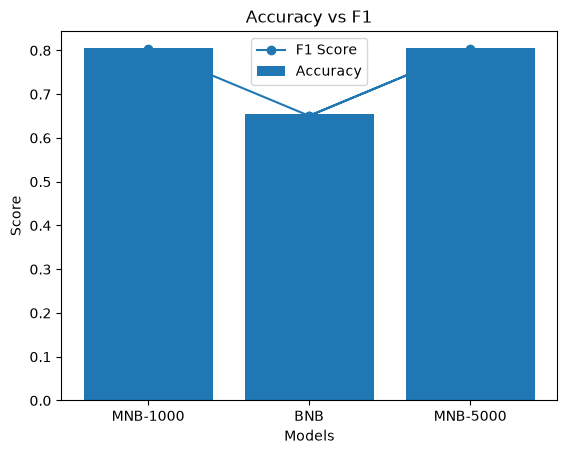

In [31]:
models = ["MNB-1000", "BNB", "MNB-5000", "BNB"]

acc = [acc_m1, acc_b1, acc_m2, acc_b2]
f1 = [f1_m1, f1_b1, f1_m2, f1_b2]

plt.bar(models, acc, label="Accuracy")
plt.plot(models, f1, marker="o", label="F1 Score")

plt.xlabel("Models")
plt.ylabel("Score")
plt.title("Accuracy vs F1")
plt.legend()
plt.show()